# Opgave 1

## 1A

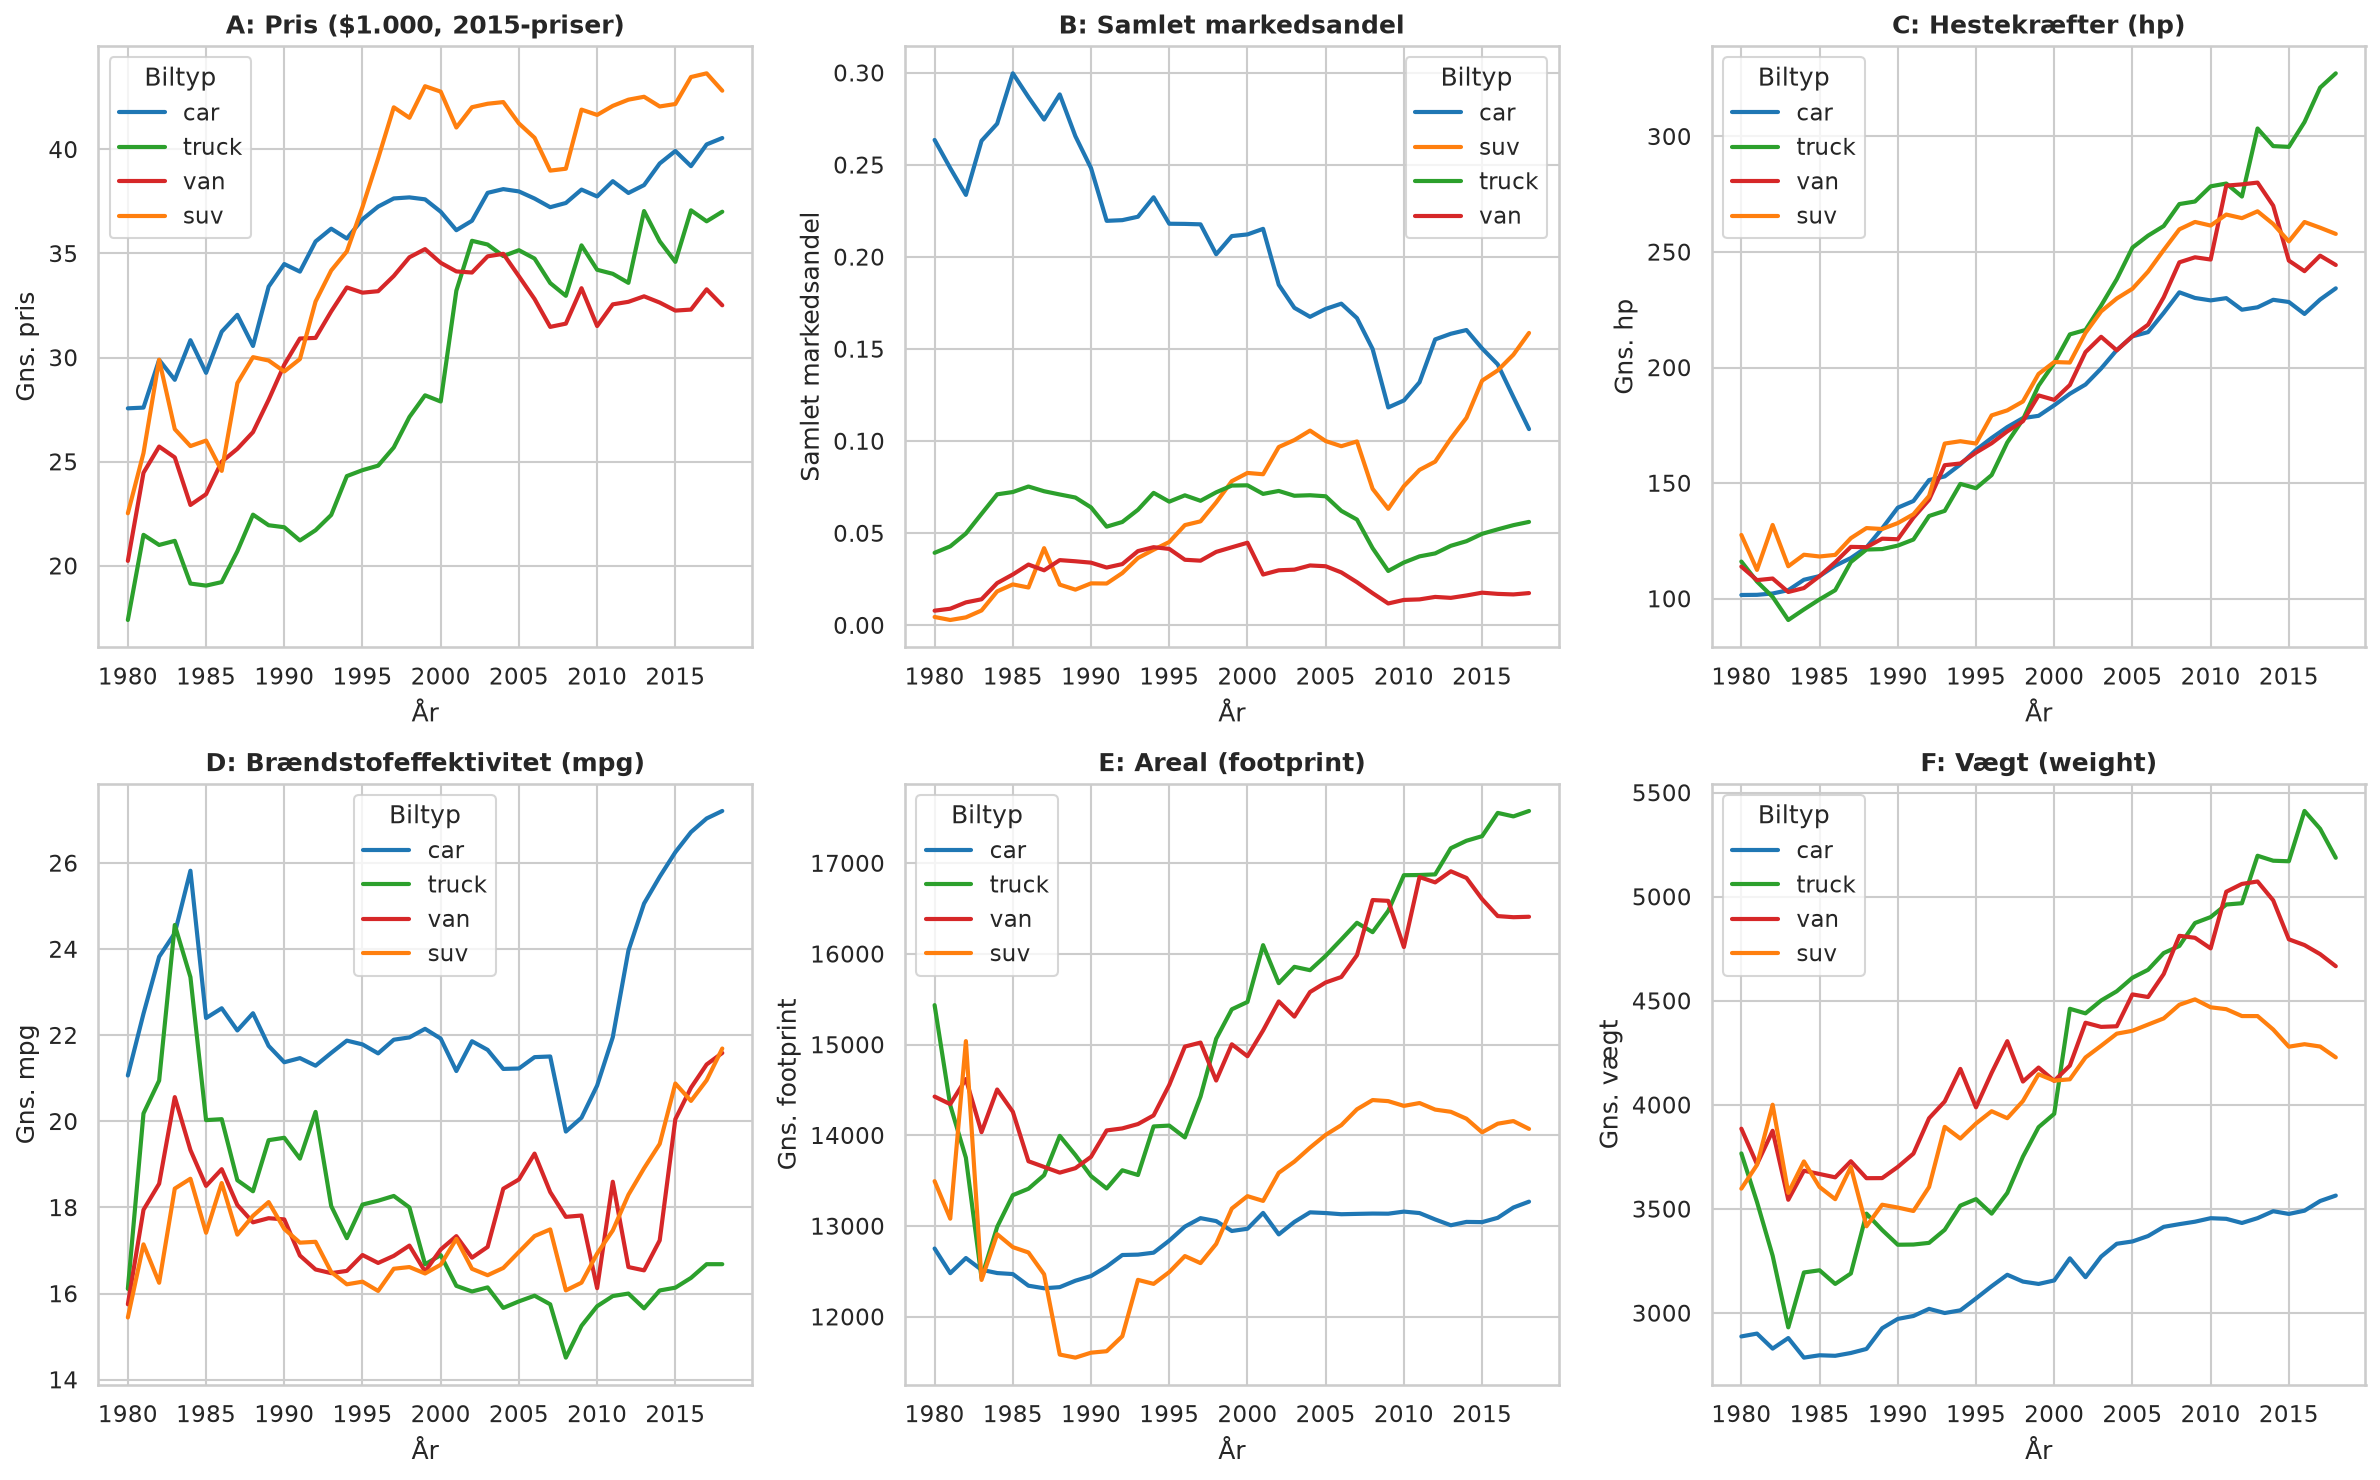

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cars.csv')

type_cols = ['car', 'suv', 'truck', 'van']

def get_body_type(row):
    for c in type_cols:
        if row[c] == 1:
            return c
    return 'other'

df['body_type'] = df.apply(get_body_type, axis=1)

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.dpi': 150})

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

palette = {'car': '#1f77b4', 'suv': '#ff7f0e', 'truck': '#2ca02c', 'van': '#d62728'}

sns.lineplot(data=df, x='year', y='price', hue='body_type',
             palette=palette, ax=axes[0, 0], errorbar=None, linewidth=2)
axes[0, 0].set_title('A: Pris ($1.000, 2015-priser)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('År')
axes[0, 0].set_ylabel('Gns. pris')
axes[0, 0].legend(title='Biltyp')

ms_time = df.groupby(['year', 'body_type'])['market_share'].sum().reset_index()
sns.lineplot(data=ms_time, x='year', y='market_share', hue='body_type', palette=palette, ax=axes[0, 1], linewidth=2)
axes[0, 1].set_title('B: Samlet markedsandel', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('År')
axes[0, 1].set_ylabel('Samlet markedsandel')
axes[0, 1].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='hp', hue='body_type',
             palette=palette, ax=axes[0, 2], errorbar=None, linewidth=2)
axes[0, 2].set_title('C: Hestekræfter (hp)', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('År')
axes[0, 2].set_ylabel('Gns. hp')
axes[0, 2].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='mpg', hue='body_type',
             palette=palette, ax=axes[1, 0], errorbar=None, linewidth=2)
axes[1, 0].set_title('D: Brændstofeffektivitet (mpg)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('År')
axes[1, 0].set_ylabel('Gns. mpg')
axes[1, 0].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='footprint', hue='body_type',
             palette=palette, ax=axes[1, 1], errorbar=None, linewidth=2)
axes[1, 1].set_title('E: Areal (footprint)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('År')
axes[1, 1].set_ylabel('Gns. footprint')
axes[1, 1].legend(title='Biltyp')

sns.lineplot(data=df, x='year', y='weight', hue='body_type',
             palette=palette, ax=axes[1, 2], errorbar=None, linewidth=2)
axes[1, 2].set_title('F: Vægt (weight)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('År')
axes[1, 2].set_ylabel('Gns. vægt')
axes[1, 2].legend(title='Biltyp')

plt.tight_layout()


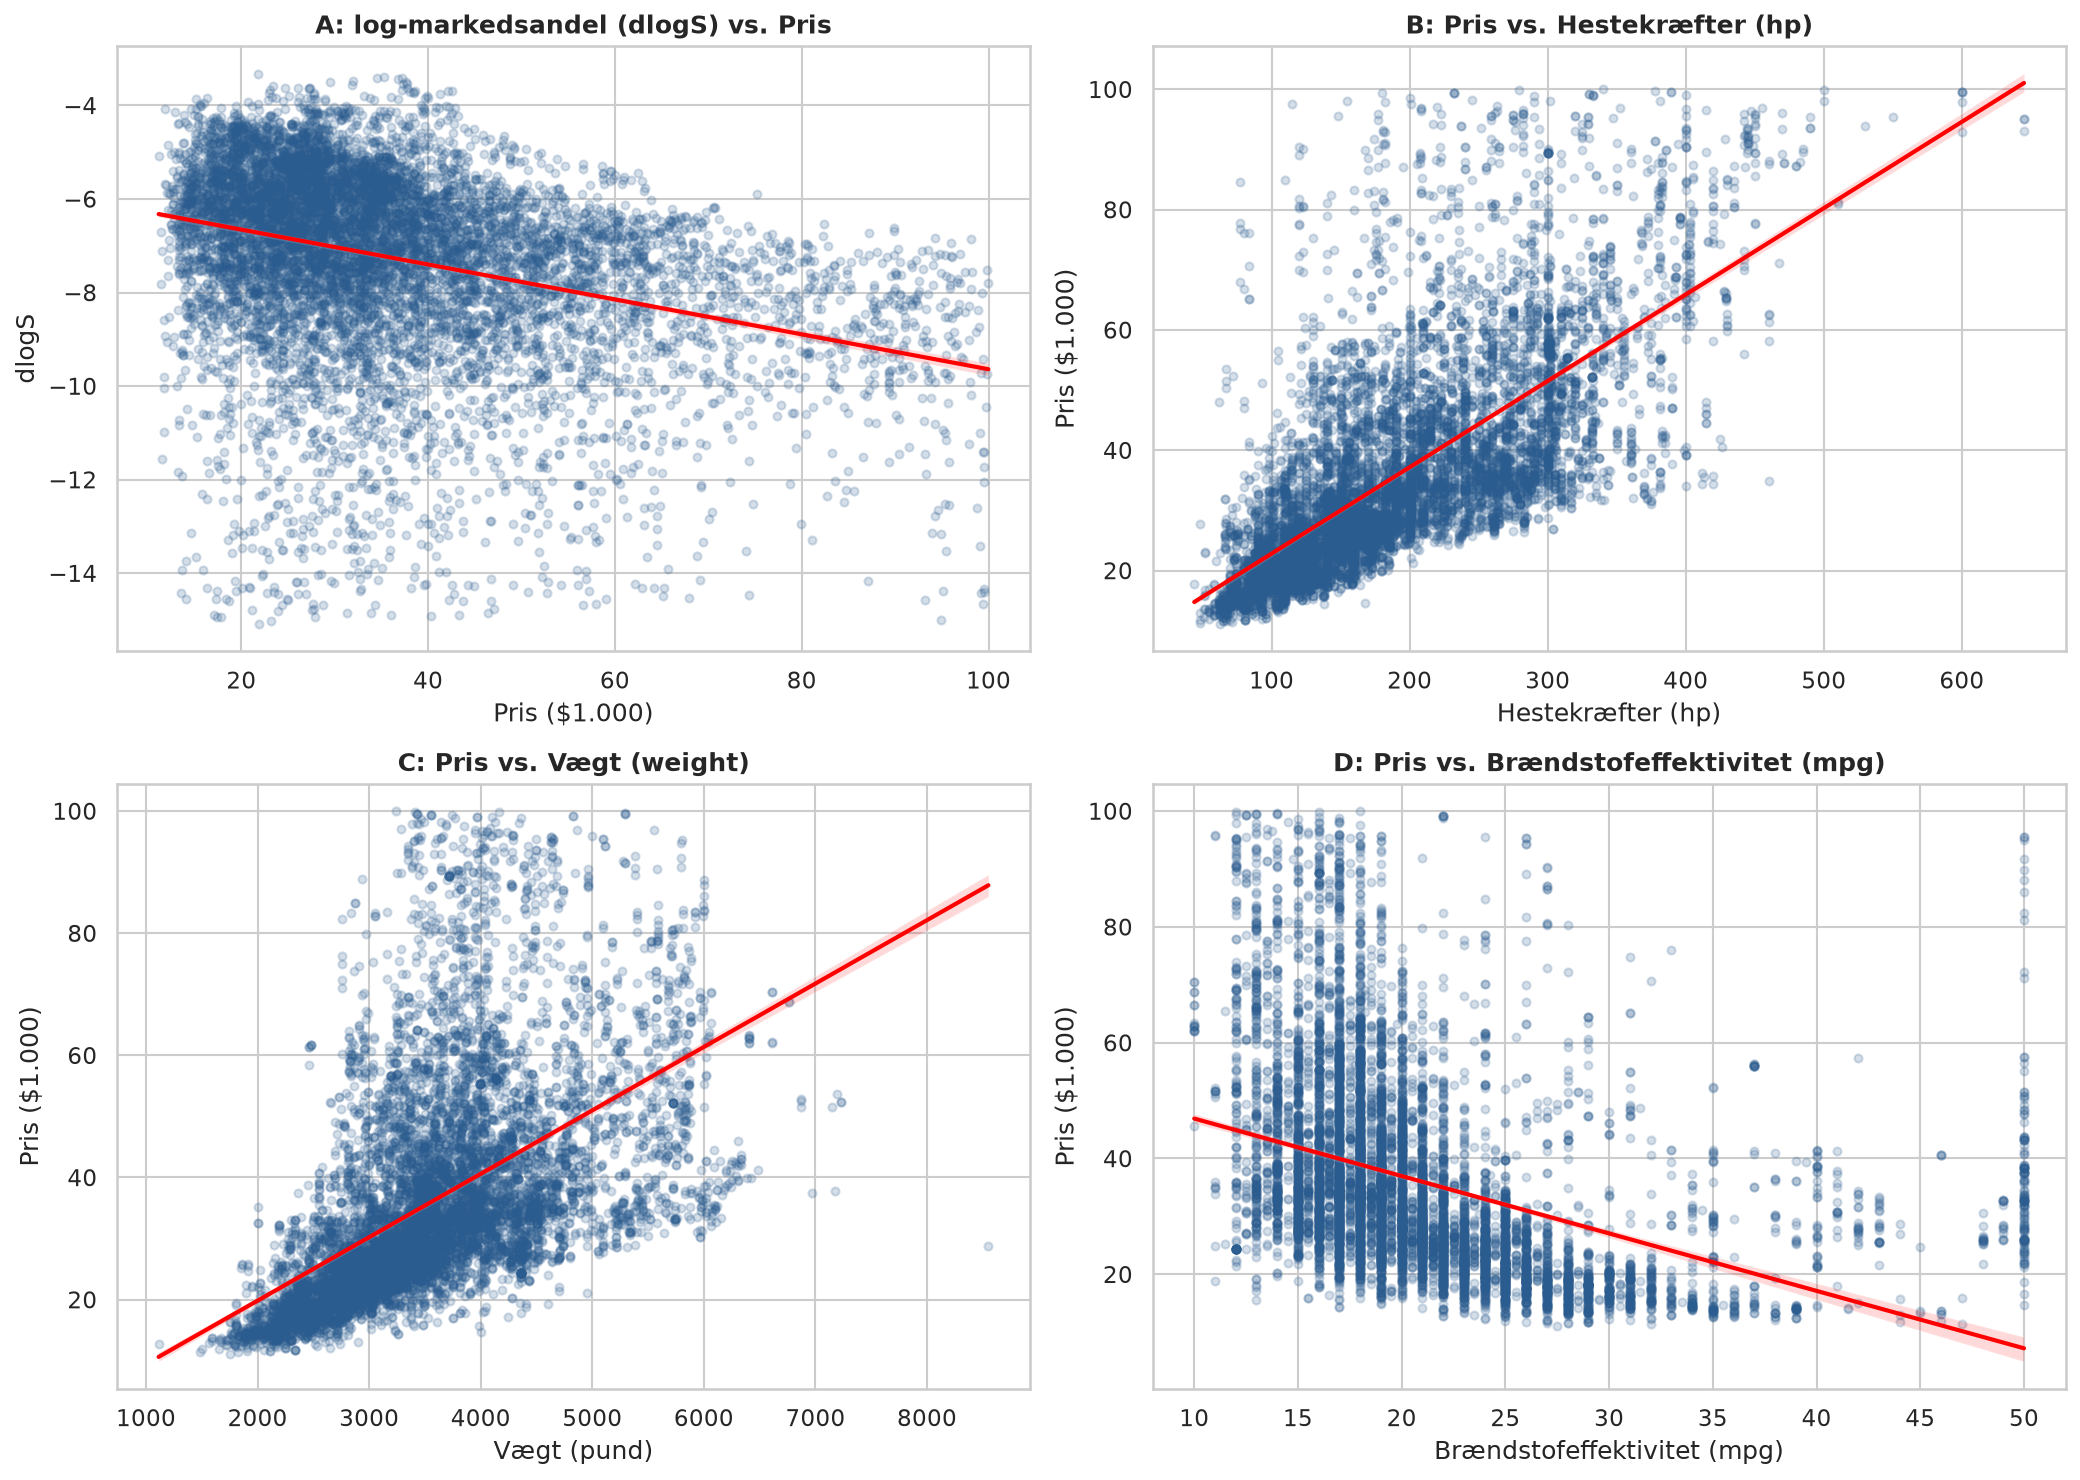

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.regplot(data=df, x='price', y='dlogS', ax=axes[0, 0], 
            scatter_kws={'alpha':0.2, 'color':'#2b5c8f', 's':15}, 
            line_kws={'color':'red', 'linewidth':2})
axes[0, 0].set_title('A: log-markedsandel (dlogS) vs. Pris', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Pris ($1.000)')
axes[0, 0].set_ylabel('dlogS')

sns.regplot(data=df, x='hp', y='price', ax=axes[0, 1], 
            scatter_kws={'alpha':0.2, 'color':'#2b5c8f', 's':15}, 
            line_kws={'color':'red', 'linewidth':2})
axes[0, 1].set_title('B: Pris vs. Hestekræfter (hp)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Hestekræfter (hp)')
axes[0, 1].set_ylabel('Pris ($1.000)')

sns.regplot(data=df, x='weight', y='price', ax=axes[1, 0], 
            scatter_kws={'alpha':0.2, 'color':'#2b5c8f', 's':15}, 
            line_kws={'color':'red', 'linewidth':2})
axes[1, 0].set_title('C: Pris vs. Vægt (weight)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Vægt (pund)')
axes[1, 0].set_ylabel('Pris ($1.000)')

sns.regplot(data=df, x='mpg', y='price', ax=axes[1, 1], 
            scatter_kws={'alpha':0.2, 'color':'#2b5c8f', 's':15}, 
            line_kws={'color':'red', 'linewidth':2})
axes[1, 1].set_title('D: Pris vs. Brændstofeffektivitet (mpg)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Brændstofeffektivitet (mpg)')
axes[1, 1].set_ylabel('Pris ($1.000)')

plt.tight_layout()

## 1B

In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

df = pd.read_csv('cars.csv')

y = df['dlogS']

X1 = sm.add_constant(df['price'])
model1 = sm.OLS(y, X1).fit()

chars2 = ['hp', 'mpg', 'height', 'footprint', 'weight', 'number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van']
X2 = sm.add_constant(df[['price'] + chars2])
model2 = sm.OLS(y, X2).fit()

year_dummies = pd.get_dummies(df['year'], prefix='y', drop_first=True, dtype=int)
X3 = pd.concat([X2, year_dummies], axis=1)
model3 = sm.OLS(y, X3).fit()

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

chars4 = ['log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight', 'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van']
X4 = sm.add_constant(df[['price'] + chars4])
X4 = pd.concat([X4, year_dummies], axis=1)
model4 = sm.OLS(y, X4).fit()

def print_model_summary(model, name):
    rss = model.ssr
    ess = model.ess
    tss = model.centered_tss
    r2 = model.rsquared
    print(f"\n================ {name} ================")
    print(f"R-squared: {r2:.6f}")
    print(f"TSS: {tss:.4f}")
    print(f"ESS: {ess:.4f}")
    print(f"RSS: {rss:.4f}")
    print("\nCoefficients:")
    params = model.params
    bse = model.bse
    tvals = model.tvalues
    pvals = model.pvalues
    
    summary_df = pd.DataFrame({
        'Coef': params,
        'Std.Err': bse,
        't-stat': tvals,
        'p-val': pvals
    })
    
    non_year = [c for c in summary_df.index if not c.startswith('y_')]
    print(summary_df.loc[non_year].round(6))

print_model_summary(model1, "Specifikation 1")
print_model_summary(model2, "Specifikation 2")
print_model_summary(model3, "Specifikation 3")
print_model_summary(model4, "Specifikation 4")


================ Specifikation 1 ================
R-squared: 0.106197
TSS: 37300.6952
ESS: 3961.2203
RSS: 33339.4749

Coefficients:
           Coef   Std.Err      t-stat  p-val
const -5.907219  0.043898 -134.567253    0.0
price -0.037326  0.001100  -33.934529    0.0

================ Specifikation 2 ================
R-squared: 0.300057
TSS: 37300.6952
ESS: 11192.3322
RSS: 26108.3630

Coefficients:
                      Coef   Std.Err     t-stat     p-val
const            -5.413798  0.290803 -18.616711  0.000000
price            -0.024260  0.001611 -15.056687  0.000000
hp               -0.003792  0.000372 -10.184646  0.000000
mpg              -0.042658  0.003656 -11.667047  0.000000
height           -0.023665  0.004828  -4.901967  0.000001
footprint         0.000354  0.000018  19.117615  0.000000
weight           -0.000714  0.000065 -10.943475  0.000000
number_trims      0.055177  0.001890  29.194357  0.000000
releaseYear      -1.064264  0.061432 -17.324233  0.000000
yearsSinceDesign -

## 1C

In [4]:
test_results = []

models = {
    'Specifikation 1': X1,
    'Specifikation 2': X2,
    'Specifikation 3': X3,
    'Specifikation 4': X4,
}

for name, X in models.items():
    model_ols = sm.OLS(y, X).fit()
    model_hc1 = sm.OLS(y, X).fit(cov_type='HC1')

    test_results.append({
        'Specifikation': name,
        'alpha_hat': model_ols.params['price'],
        'SE': model_ols.bse['price'],
        't-stat': model_ols.tvalues['price'],
        'p-val': model_ols.pvalues['price'],
        'SE (HC1 Robust)': model_hc1.bse['price'],
        't-stat (HC1 Robust)': model_hc1.tvalues['price'],
        'p-val (HC1 Robust)': model_hc1.pvalues['price'],
    })

results_df = pd.DataFrame(test_results)
print(results_df.to_string(index=False))

  Specifikation  alpha_hat       SE     t-stat         p-val  SE (HC1 Robust)  t-stat (HC1 Robust)  p-val (HC1 Robust)
Specifikation 1  -0.037326 0.001100 -33.934529 1.297761e-238         0.001044           -35.756000       5.337613e-280
Specifikation 2  -0.024260 0.001611 -15.056687  1.166519e-50         0.001616           -15.013312        6.007165e-51
Specifikation 3  -0.036958 0.001687 -21.903210 8.010056e-104         0.001694           -21.818086       1.562628e-105
Specifikation 4  -0.029820 0.001422 -20.969296  1.660767e-95         0.001401           -21.281838       1.672540e-100
